In [1]:

import pandas as pd
import numpy as np
import os

# Load the dataset
file_path = '/content/Occupancy_Estimation.csv'
df = pd.read_csv(file_path)

# Display dataset information
print("=" * 50)
print("ROOM OCCUPANCY ESTIMATION DATASET")
print("=" * 50)

print("\n1. Dataset Shape:")
print(df.shape)

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. First 5 Records:")
display(df.head())

print("\n4. Dataset Information:")
df.info()

print("\n5. Missing Values:")
print(df.isnull().sum())

print("\n6. Duplicate Records:")
print(df.duplicated().sum())

print("\n7. Target Class Distribution:")
print(df['Room_Occupancy_Count'].value_counts().sort_index())

print("\n8. Statistical Summary:")
display(df.describe())


ROOM OCCUPANCY ESTIMATION DATASET

1. Dataset Shape:
(10129, 19)

2. Column Names:
['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count']

3. First 5 Records:


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1



4. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10129 entries, 0 to 10128
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  10129 non-null  object 
 1   Time                  10129 non-null  object 
 2   S1_Temp               10129 non-null  float64
 3   S2_Temp               10129 non-null  float64
 4   S3_Temp               10129 non-null  float64
 5   S4_Temp               10129 non-null  float64
 6   S1_Light              10129 non-null  int64  
 7   S2_Light              10129 non-null  int64  
 8   S3_Light              10129 non-null  int64  
 9   S4_Light              10129 non-null  int64  
 10  S1_Sound              10129 non-null  float64
 11  S2_Sound              10129 non-null  float64
 12  S3_Sound              10129 non-null  float64
 13  S4_Sound              10129 non-null  float64
 14  S5_CO2                10129 non-null  int64  

,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
count,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.00000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000,10129.000000
mean,25.454012,25.546059,25.056621,25.754125,25.445059,26.01629,34.248494,13.220259,0.168178,0.120066,0.158119,0.103840,460.860401,-0.004830,0.090137,0.079574,0.398559
std,0.351351,0.586325,0.427283,0.356434,51.011264,67.30417,58.400744,19.602219,0.316709,0.266503,0.413637,0.120683,199.964940,1.164990,0.286392,0.270645,0.893633
min,24.940000,24.750000,24.440000,24.940000,0.000000,0.00000,0.000000,0.000000,0.060000,0.040000,0.040000,0.050000,345.000000,-6.296154,0.000000,0.000000,0.000000
25%,25.190000,25.190000,24.690000,25.440000,0.000000,0.00000,0.000000,0.000000,0.070000,0.050000,0.060000,0.060000,355.000000,-0.046154,0.000000,0.000000,0.000000
50%,25.380000,25.380000,24.940000,25.750000,0.000000,0.00000,0.000000,0.000000,0.080000,0.050000,0.060000,0.080000,360.000000,0.000000,0.000000,0.000000,0.000000
75%,25.630000,25.630000,25.380000,26.000000,12.000000,14.00000,50.000000,22.000000,0.080000,0.060000,0.070000,0.100000,465.000000,0.000000,0.000000,0.000000,0.000000
max,26.380000,29.000000,26.190000,26.560000,165.000000,258.00000,280.000000,74.000000,3.880000,3.440000,3.670000,3.400000,1270.000000,8.980769,1.000000,1.000000,3.000000


In [2]:

from sklearn.model_selection import train_test_split

# Define target column
target_column = 'Room_Occupancy_Count'

# Exclude Date and Time from input features
X = df.drop(columns=['Date', 'Time', target_column])
y = df[target_column]

# Verify feature selection
print("Number of input features:", X.shape[1])
print("Input features:")
print(X.columns.tolist())

print("\nTarget classes:")
print(sorted(y.unique()))

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Check class distribution in training data
print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

# Check class distribution in testing data
print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

# Prepare test CSV for Streamlit
test_data = X_test.copy()
test_data[target_column] = y_test

test_data.to_csv('/content/test_data.csv', index=False)

print("\nTest dataset saved successfully as test_data.csv")


Number of input features: 16
Input features:
['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']

Target classes:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

Training Data Shape: (8103, 16)
Testing Data Shape: (2026, 16)

Training Class Distribution:
Room_Occupancy_Count
0    6582
1     367
2     599
3     555
Name: count, dtype: int64

Testing Class Distribution:
Room_Occupancy_Count
0    1646
1      92
2     149
3     139
Name: count, dtype: int64

Test dataset saved successfully as test_data.csv


In [3]:

import os
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Create directory for saved models
os.makedirs('/content/model', exist_ok=True)

# Define five classification models
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=2000, random_state=42))
    ]),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=5))
    ]),

    'Naive Bayes': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', GaussianNB())
    ]),

    'Support Vector Machine': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', SVC(
            kernel='rbf',
            probability=True,
            random_state=42
        ))
    ])
}

# Define model file names
model_files = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib'
}

# Store evaluation results
results = []

# Train and evaluate each model
for name, model in models.items():

    print(f"\nTraining {name}...")

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate prediction probabilities
    y_prob = model.predict_proba(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    auc = roc_auc_score(
        y_test,
        y_prob,
        multi_class='ovr',
        average='macro'
    )

    precision = precision_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average='macro',
        zero_division=0
    )

    mcc = matthews_corrcoef(y_test, y_pred)

    # Save trained model
    model_path = '/content/model/' + model_files[name]
    joblib.dump(model, model_path)

    # Store results
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'MCC': mcc
    })

    print(f"{name} completed successfully.")

# Create comparison table
results_df = pd.DataFrame(results)

# Display results
print("\n" + "=" * 90)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 90)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'AUC': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'MCC': '{:.4f}'
    })
)

# Save evaluation results
results_df.to_csv(
    '/content/model_comparison.csv',
    index=False
)

print("\nAll five models trained and saved successfully!")
print("Model directory: /content/model/")
print("Metrics file: /content/model_comparison.csv")



Training Logistic Regression...
Logistic Regression completed successfully.

Training Decision Tree...
Decision Tree completed successfully.

Training KNN...
KNN completed successfully.

Training Naive Bayes...
Naive Bayes completed successfully.

Training Support Vector Machine...
Support Vector Machine completed successfully.

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9946,0.9996,0.9850,0.9803,0.9822,0.9834
1,Decision Tree,0.9961,0.9929,0.9871,0.9874,0.9871,0.9880
2,KNN,0.9951,0.9979,0.9823,0.9845,0.9833,0.9850
3,Naive Bayes,0.9615,0.9931,0.8809,0.8880,0.8821,0.8844
4,Support Vector Machine,0.9970,0.9996,0.9898,0.9925,0.9911,0.9910



All five models trained and saved successfully!
Model directory: /content/model/
Metrics file: /content/model_comparison.csv



Logistic Regression
              precision    recall  f1-score   support

       Empty       1.00      1.00      1.00      1646
  One Person       1.00      1.00      1.00        92
  Two People       0.95      0.99      0.97       149
Three People       0.99      0.93      0.96       139

    accuracy                           0.99      2026
   macro avg       0.98      0.98      0.98      2026
weighted avg       0.99      0.99      0.99      2026



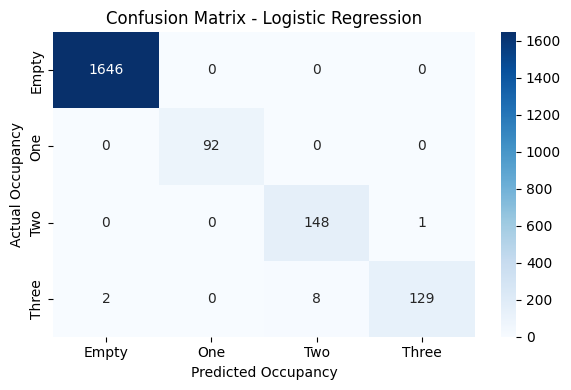


Decision Tree
              precision    recall  f1-score   support

       Empty       1.00      1.00      1.00      1646
  One Person       0.99      1.00      0.99        92
  Two People       0.97      0.99      0.98       149
Three People       0.99      0.96      0.97       139

    accuracy                           1.00      2026
   macro avg       0.99      0.99      0.99      2026
weighted avg       1.00      1.00      1.00      2026



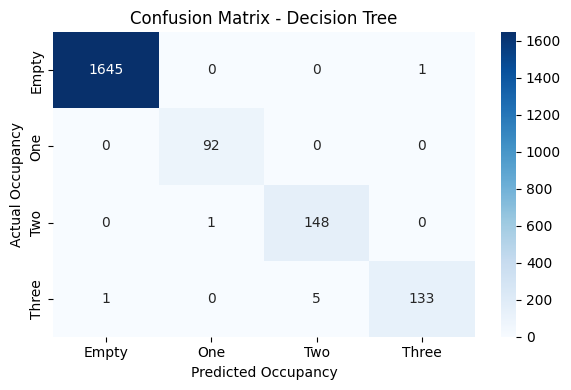


KNN
              precision    recall  f1-score   support

       Empty       1.00      1.00      1.00      1646
  One Person       0.99      0.99      0.99        92
  Two People       0.95      0.99      0.97       149
Three People       0.99      0.96      0.97       139

    accuracy                           1.00      2026
   macro avg       0.98      0.98      0.98      2026
weighted avg       1.00      1.00      1.00      2026



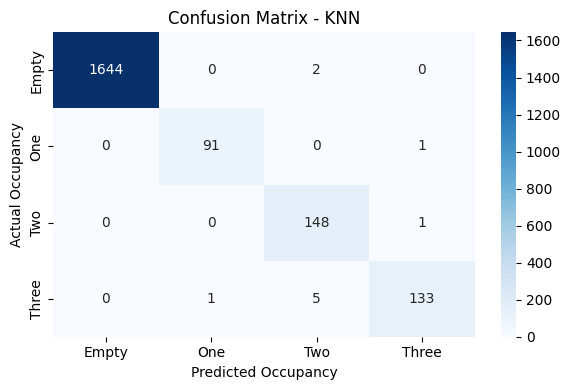


Naive Bayes
              precision    recall  f1-score   support

       Empty       1.00      0.99      0.99      1646
  One Person       1.00      0.97      0.98        92
  Two People       0.77      0.92      0.84       149
Three People       0.76      0.68      0.71       139

    accuracy                           0.96      2026
   macro avg       0.88      0.89      0.88      2026
weighted avg       0.96      0.96      0.96      2026



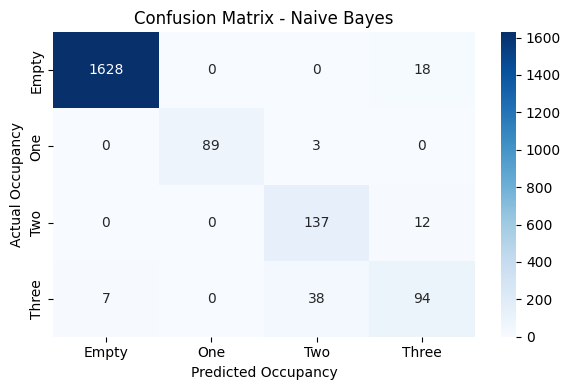


Support Vector Machine
              precision    recall  f1-score   support

       Empty       1.00      1.00      1.00      1646
  One Person       1.00      1.00      1.00        92
  Two People       0.97      1.00      0.99       149
Three People       0.99      0.97      0.98       139

    accuracy                           1.00      2026
   macro avg       0.99      0.99      0.99      2026
weighted avg       1.00      1.00      1.00      2026



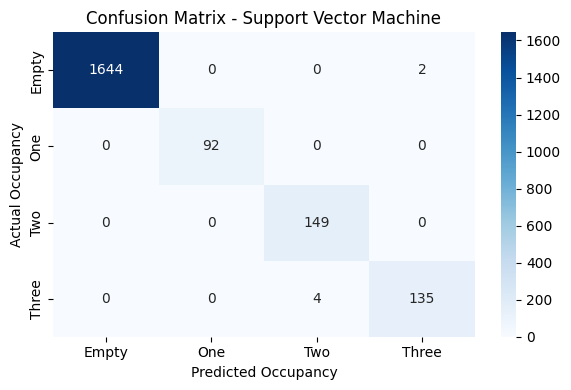

In [4]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

model_files = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

os.makedirs("/content/evaluation_reports", exist_ok=True)

for model_name, file_name in model_files.items():

    model = joblib.load("/content/model/" + file_name)
    y_pred = model.predict(X_test)

    print("\n" + "=" * 60)
    print(model_name)
    print("=" * 60)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=["Empty", "One Person", "Two People", "Three People"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Empty", "One", "Two", "Three"],
        yticklabels=["Empty", "One", "Two", "Three"]
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Occupancy")
    plt.ylabel("Actual Occupancy")
    plt.tight_layout()

    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(
        f"/content/evaluation_reports/{safe_name}_confusion_matrix.png"
    )
    plt.show()

In [7]:
from google.colab import files
import shutil

# Create a ZIP containing all five trained models
shutil.make_archive(
    "/content/trained_models",
    "zip",
    "/content/model"
)

# Download the model ZIP
files.download("/content/trained_models.zip")

# Download test dataset
files.download("/content/test_data.csv")

# Download model comparison
files.download("/content/model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>